In [1]:
#data understanding/loading
import pandas as pd

In [2]:
d=pd.read_csv("salary_data.csv")
d

,YearsExperience,Salary
0,1.1,39343.0
1,1.3,46205.0
2,1.5,37731.0
3,2.0,43525.0
4,2.2,39891.0
5,2.9,56642.0
6,3.0,60150.0
7,3.2,54445.0
8,3.2,64445.0
9,3.7,57189.0


In [3]:
d.describe()

,YearsExperience,Salary
count,29.000000,29.000000
mean,5.358621,76353.758621
std,2.877067,27818.320191
min,1.100000,37731.000000
25%,3.200000,56642.000000
50%,4.900000,64445.000000
75%,7.900000,101302.000000
max,10.500000,122391.000000


In [4]:
#feature selection/engineering(here we tell feature data and target data)
x=d[['YearsExperience']]
x
y=d.iloc[:,1]
x

,YearsExperience
0,1.1
1,1.3
2,1.5
3,2.0
4,2.2
5,2.9
6,3.0
7,3.2
8,3.2
9,3.7


In [5]:
#Train Test Spliting (split data before training a model)
from sklearn.model_selection import train_test_split

In [6]:
x_train,x_test,y_train,y_test=train_test_split(x,y,test_size=0.2,random_state=42)

In [7]:
x_train

,YearsExperience
21,7.9
0,1.1
26,9.6
13,4.5
15,5.1
11,4.0
17,5.9
1,1.3
4,2.2
5,2.9


In [8]:
x_test

,YearsExperience
27,10.3
16,5.3
12,4.1
22,8.2
8,3.2
9,3.7


In [9]:
#Model Selection / Model Training stage
from sklearn.linear_model import LinearRegression

In [10]:
lr=LinearRegression()
lr.fit(x_train,y_train)#Trains the model using training data

,"fit_intercept fit_intercept: bool, default=TrueWhether to calculate the intercept for this model. If setto False, no intercept will be used in calculations(i.e. data is expected to be centered).",True
,"copy_X copy_X: bool, default=TrueIf True, X will be copied; else, it may be overwritten.",True
,"tol tol: float, default=1e-6The precision of the solution (`coef_`) is determined by `tol` whichspecifies a different convergence criterion for the `lsqr` solver.`tol` is set as `atol` and `btol` of :func:`scipy.sparse.linalg.lsqr` whenfitting on sparse training data. This parameter has no effect when fittingon dense data... versionadded:: 1.7",1e-06
,"n_jobs n_jobs: int, default=NoneThe number of jobs to use for the computation. This will only providespeedup in case of sufficiently large problems, that is if firstly`n_targets > 1` and secondly `X` is sparse or if `positive` is setto `True`. ``None`` means 1 unless in a:obj:`joblib.parallel_backend` context. ``-1`` means using allprocessors. See :term:`Glossary ` for more details.",None
,"positive positive: bool, default=FalseWhen set to ``True``, forces the coefficients to be positive. Thisoption is only supported for dense arrays.For a comparison between a linear regression model with positive constraintson the regression coefficients and a linear regression without such constraints,see :ref:`sphx_glr_auto_examples_linear_model_plot_nnls.py`... versionadded:: 0.24",False


In [11]:
#Model Evaluation / Prediction stage
y_pred=lr.predict(x_test)
y_pred

array([121655.938965  ,  75150.79725412,  63989.56324351, 102123.77944643,
        55618.63773556,  60269.15190664])

In [12]:
y_test

27    122391.0
16     83088.0
12     56957.0
22    113812.0
8      64445.0
9      57189.0
Name: Salary, dtype: float64

In [13]:
#Model Evaluation stage
from sklearn.metrics import r2_score

In [14]:
r2_score(y_test,y_pred)

0.9195652708643394

In [16]:
years = float(input("Enter Years of Experience: "))
years = [[years]]  # reshape to 2D
salary = lr.predict(years)
print("Predicted Employee Salary:", salary[0])

Enter Years of Experience:  18


Predicted Employee Salary: 193273.85719974554


C:\Users\guna9\anaconda3\Lib\site-packages\sklearn\utils\validation.py:2691: UserWarning: X does not have valid feature names, but LinearRegression was fitted with feature names
  warnings.warn(


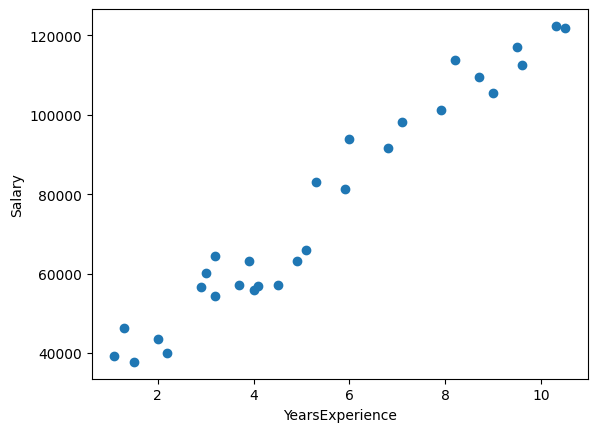

In [17]:
#Visualising Data Using Plot
import matplotlib.pyplot as plt
plt.scatter(d['YearsExperience'], d['Salary'])
plt.xlabel("YearsExperience")
plt.ylabel("Salary")
plt.show()


In [18]:
# Coefficient and intercept
print("Slope:", lr.coef_[0])
print("Intercept:", lr.intercept_)


Slope: 9301.02834217501
Intercept: 25855.347040595385


In [19]:
# More metrics
from sklearn.metrics import mean_absolute_error, mean_squared_error
import numpy as np
print("MAE:", mean_absolute_error(y_test, y_pred))
print("RMSE:", np.sqrt(mean_squared_error(y_test, y_pred)))


MAE: 6549.926958174839
RMSE: 7494.475234335828


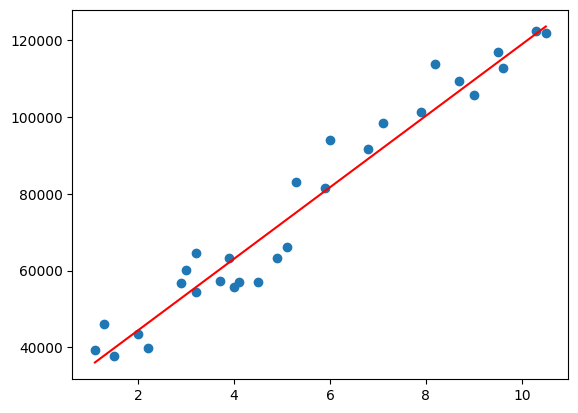

In [20]:
# Regression line plot
plt.scatter(x, y)
plt.plot(x, lr.predict(x), color='red')
plt.show()